In [1]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score, classification_report
from sklearn.model_selection import StratifiedKFold
import matplotlib.pyplot as plt

# Đọc dữ liệu đã tiền xử lý
train = pd.read_csv('../data/processed/train.csv')
val = pd.read_csv('../data/processed/val.csv')
test = pd.read_csv('../data/processed/test.csv')

# Tách X, y
X_train = train.drop(columns=['target'])
y_train = train['target']
X_val = val.drop(columns=['target'])
y_val = val['target']
X_test = test.drop(columns=['target'])
y_test = test['target']

print("Train:", X_train.shape, "| Good:", (y_train==1).sum(), "Bad:", (y_train==0).sum())
print("Val:  ", X_val.shape,   "| Good:", (y_val==1).sum(),   "Bad:", (y_val==0).sum())
print("Test: ", X_test.shape,  "| Good:", (y_test==1).sum(),  "Bad:", (y_test==0).sum())

Train: (600, 61) | Good: 420 Bad: 180
Val:   (200, 61) | Good: 140 Bad: 60
Test:  (200, 61) | Good: 140 Bad: 60


In [2]:
# BASELINE: Đoán tất cả là Good (1)
y_pred_baseline = np.ones(len(y_val), dtype=int)

# Confusion matrix
cm_baseline = confusion_matrix(y_val, y_pred_baseline)
print("=== BASELINE: Đoán tất cả là Good ===")
print("Confusion matrix:")
print(cm_baseline)
print(f"\nTN={cm_baseline[0,0]}, FP={cm_baseline[0,1]}")
print(f"FN={cm_baseline[1,0]}, TP={cm_baseline[1,1]}")

# Cost = 5*FP + 1*FN (theo ma trận chi phí UCI)
# FP = dự đoán Good cho người Bad → chi phí 5
# FN = dự đoán Bad cho người Good → chi phí 1
cost_baseline = 5 * cm_baseline[0,1] + 1 * cm_baseline[1,0]
print(f"\nTổng chi phí baseline: {cost_baseline}")
print(f"(= 5 × {cm_baseline[0,1]} FP + 1 × {cm_baseline[1,0]} FN)")

=== BASELINE: Đoán tất cả là Good ===
Confusion matrix:
[[  0  60]
 [  0 140]]

TN=0, FP=60
FN=0, TP=140

Tổng chi phí baseline: 300
(= 5 × 60 FP + 1 × 0 FN)


In [3]:
def total_cost(y_true, y_pred):
    """Tính tổng chi phí theo ma trận 5:1 của UCI.
    FP (dự đoán Good cho người Bad) = 5
    FN (dự đoán Bad cho người Good) = 1
    """
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    cost = 5 * fp + 1 * fn
    return cost, cm

# Kiểm tra hàm với baseline
cost_check, _ = total_cost(y_val, y_pred_baseline)
print(f"Kiểm tra hàm cost với baseline: {cost_check} (phải = 300)")

Kiểm tra hàm cost với baseline: 300 (phải = 300)


In [4]:
# Huấn luyện Logistic Regression
# max_iter=1000 để đảm bảo hội tụ (dữ liệu 61 features)
# class_weight='balanced' để xử lý mất cân bằng 70/30
lr = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
lr.fit(X_train, y_train)

# Dự đoán xác suất trên val
y_val_proba = lr.predict_proba(X_val)[:, 1]  # xác suất là Good

print("Đã huấn luyện Logistic Regression")
print(f"Số features: {len(lr.coef_[0])}")
print(f"Số iterations: {lr.n_iter_}")
print(f"\nXác suất dự đoán trên val (5 dòng đầu): {y_val_proba[:5].round(3)}")

Đã huấn luyện Logistic Regression
Số features: 61
Số iterations: [55]

Xác suất dự đoán trên val (5 dòng đầu): [0.755 0.654 0.757 0.817 0.477]


In [5]:
# In hệ số log-odds, sắp xếp theo trị tuyệt đối giảm dần
coef_df = pd.DataFrame({
    'feature': X_train.columns,
    'coef': lr.coef_[0]
})
coef_df['abs_coef'] = coef_df['coef'].abs()
coef_df = coef_df.sort_values('abs_coef', ascending=False).reset_index(drop=True)

print("=== HỆ SỐ LOG-ODDS (sắp xếp theo ảnh hưởng) ===")
print("Hệ số dương → tăng khả năng Good")
print("Hệ số âm → tăng khả năng Bad\n")
print(coef_df[['feature', 'coef']].head(15).to_string(index=False))

print("\n=== 5 HỆ SỐ ẢNH HƯỞNG MẠNH NHẤT ===")
for i in range(5):
    row = coef_df.iloc[i]
    direction = "→ GOOD" if row['coef'] > 0 else "→ BAD"
    print(f"{i+1}. {row['feature']}: {row['coef']:.4f} {direction}")

=== HỆ SỐ LOG-ODDS (sắp xếp theo ảnh hưởng) ===
Hệ số dương → tăng khả năng Good
Hệ số âm → tăng khả năng Bad

                 feature      coef
             purpose_A41  1.209350
     checking_status_A14  0.911891
      credit_history_A34  0.886450
             purpose_A46 -0.877149
      other_parties_A103  0.781729
     checking_status_A11 -0.768829
     foreign_worker_A202  0.626415
     foreign_worker_A201 -0.620990
 property_magnitude_A124 -0.600366
      savings_status_A61 -0.599954
             purpose_A40 -0.598421
      credit_history_A31 -0.592108
          employment_A74  0.588945
      other_parties_A102 -0.466734
other_payment_plans_A143  0.436518

=== 5 HỆ SỐ ẢNH HƯỞNG MẠNH NHẤT ===
1. purpose_A41: 1.2094 → GOOD
2. checking_status_A14: 0.9119 → GOOD
3. credit_history_A34: 0.8865 → GOOD
4. purpose_A46: -0.8771 → BAD
5. other_parties_A103: 0.7817 → GOOD


In [6]:
# Đánh giá tại ngưỡng 0.5 (mặc định)
y_val_pred_05 = (y_val_proba >= 0.5).astype(int)

cost_05, cm_05 = total_cost(y_val, y_val_pred_05)

print("=== ĐÁNH GIÁ TẠI NGƯỠNG 0.5 ===")
print("Confusion matrix:")
print(cm_05)
print(f"\nTN={cm_05[0,0]}, FP={cm_05[0,1]}")
print(f"FN={cm_05[1,0]}, TP={cm_05[1,1]}")
print(f"\nTổng chi phí: {cost_05}")
print(f"Baseline: 300")
print(f"Cải thiện: {300 - cost_05} ({((300 - cost_05)/300*100):.1f}%)")

# AUC
auc_05 = roc_auc_score(y_val, y_val_proba)
print(f"\nAUC: {auc_05:.4f}")

=== ĐÁNH GIÁ TẠI NGƯỠNG 0.5 ===
Confusion matrix:
[[ 44  16]
 [ 32 108]]

TN=44, FP=16
FN=32, TP=108

Tổng chi phí: 112
Baseline: 300
Cải thiện: 188 (62.7%)

AUC: 0.8194


=== TÌM NGƯỠNG TỐI ƯU ===
Ngưỡng tối ưu: 0.70
Chi phí tại ngưỡng tối ưu: 82
Chi phí tại ngưỡng 0.5: 112
Cải thiện thêm: 30

Bảng ngưỡng và chi phí:
 threshold  cost  FP  FN
      0.10   252  50   2
      0.15   215  42   5
      0.20   206  39  11
      0.25   183  34  13
      0.30   174  31  19
      0.35   157  27  22
      0.40   146  24  26
      0.45   139  22  29
      0.50   112  16  32
      0.55   107  14  37
      0.60   105  12  45
      0.65    91   8  51
      0.70    82   3  67
      0.75    92   3  77
      0.80    96   2  86
      0.85   108   2  98
      0.90   117   0 117


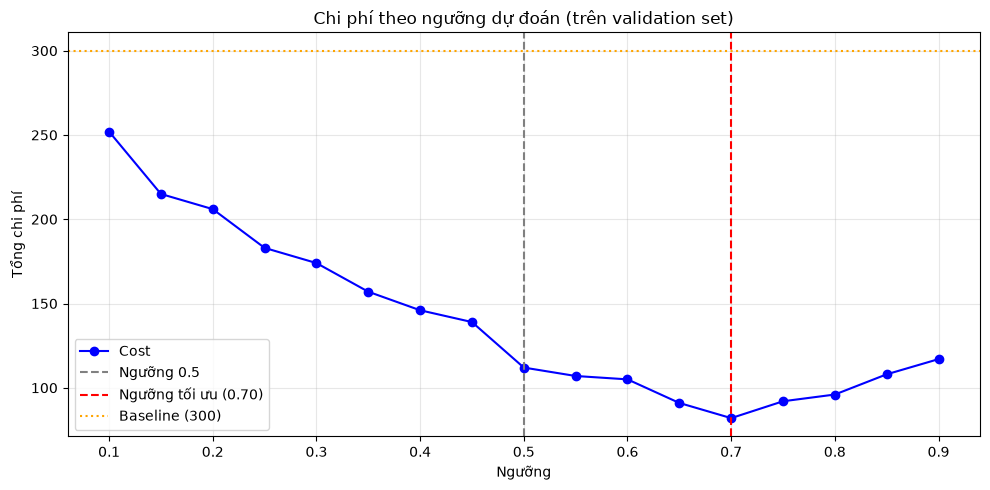

In [7]:
# Quét ngưỡng từ 0.1 đến 0.9, tìm ngưỡng minimize cost
thresholds = np.arange(0.1, 0.91, 0.05)
costs = []
fps = []
fns = []

for t in thresholds:
    y_pred_t = (y_val_proba >= t).astype(int)
    c, cm = total_cost(y_val, y_pred_t)
    costs.append(c)
    fps.append(cm[0,1])
    fns.append(cm[1,0])

# Tìm ngưỡng tối ưu
optimal_idx = np.argmin(costs)
optimal_threshold = thresholds[optimal_idx]
optimal_cost = costs[optimal_idx]

print("=== TÌM NGƯỠNG TỐI ƯU ===")
print(f"Ngưỡng tối ưu: {optimal_threshold:.2f}")
print(f"Chi phí tại ngưỡng tối ưu: {optimal_cost}")
print(f"Chi phí tại ngưỡng 0.5: {cost_05}")
print(f"Cải thiện thêm: {cost_05 - optimal_cost}")

print("\nBảng ngưỡng và chi phí:")
results = pd.DataFrame({
    'threshold': thresholds.round(2),
    'cost': costs,
    'FP': fps,
    'FN': fns
})
print(results.to_string(index=False))

# Vẽ đường cong cost theo ngưỡng
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(thresholds, costs, 'b-o', label='Cost')
ax.axvline(0.5, color='gray', linestyle='--', label='Ngưỡng 0.5')
ax.axvline(optimal_threshold, color='red', linestyle='--', label=f'Ngưỡng tối ưu ({optimal_threshold:.2f})')
ax.axhline(300, color='orange', linestyle=':', label='Baseline (300)')
ax.set_xlabel('Ngưỡng')
ax.set_ylabel('Tổng chi phí')
ax.set_title('Chi phí theo ngưỡng dự đoán (trên validation set)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
# Đánh giá trên TEST SET với ngưỡng tối ưu (0.70)
y_test_proba = lr.predict_proba(X_test)[:, 1]
y_test_pred_optimal = (y_test_proba >= optimal_threshold).astype(int)
y_test_pred_05 = (y_test_proba >= 0.5).astype(int)

cost_test_optimal, cm_test_optimal = total_cost(y_test, y_test_pred_optimal)
cost_test_05, cm_test_05 = total_cost(y_test, y_test_pred_05)

print("=== ĐÁNH GIÁ TRÊN TEST SET ===")
print(f"\nTại ngưỡng 0.5:")
print(f"  Confusion matrix: {cm_test_05.tolist()}")
print(f"  TN={cm_test_05[0,0]}, FP={cm_test_05[0,1]}, FN={cm_test_05[1,0]}, TP={cm_test_05[1,1]}")
print(f"  Chi phí: {cost_test_05}")

print(f"\nTại ngưỡng tối ưu {optimal_threshold:.2f}:")
print(f"  Confusion matrix: {cm_test_optimal.tolist()}")
print(f"  TN={cm_test_optimal[0,0]}, FP={cm_test_optimal[0,1]}, FN={cm_test_optimal[1,0]}, TP={cm_test_optimal[1,1]}")
print(f"  Chi phí: {cost_test_optimal}")

print(f"\nBaseline trên test (đoán tất cả Good): 5 × 60 = 300")
print(f"Cải thiện so với baseline: {300 - cost_test_optimal} ({((300 - cost_test_optimal)/300*100):.1f}%)")

# AUC trên test
auc_test = roc_auc_score(y_test, y_test_proba)
print(f"\nAUC trên test: {auc_test:.4f}")

=== ĐÁNH GIÁ TRÊN TEST SET ===

Tại ngưỡng 0.5:
  Confusion matrix: [[45, 15], [41, 99]]
  TN=45, FP=15, FN=41, TP=99
  Chi phí: 116

Tại ngưỡng tối ưu 0.70:
  Confusion matrix: [[52, 8], [65, 75]]
  TN=52, FP=8, FN=65, TP=75
  Chi phí: 105

Baseline trên test (đoán tất cả Good): 5 × 60 = 300
Cải thiện so với baseline: 195 (65.0%)

AUC trên test: 0.7895


In [9]:
# K-fold với 3 seed khác nhau, báo cáo khoảng dao động
from sklearn.model_selection import StratifiedKFold

seeds = [42, 123, 2026]
results = []

for seed in seeds:
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    fold_costs = []
    fold_aucs = []

    for train_idx, val_idx in skf.split(X_train, y_train):
        X_tr, X_v = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_v = y_train.iloc[train_idx], y_train.iloc[val_idx]

        # Huấn luyện lại mô hình trên fold này
        lr_fold = LogisticRegression(max_iter=1000, random_state=seed, class_weight='balanced')
        lr_fold.fit(X_tr, y_tr)

        # Dự đoán xác suất
        y_proba_fold = lr_fold.predict_proba(X_v)[:, 1]

        # Tìm ngưỡng tối ưu trên fold này (quét nhanh)
        best_cost = float('inf')
        for t in np.arange(0.3, 0.91, 0.05):
            y_pred_fold = (y_proba_fold >= t).astype(int)
            c, _ = total_cost(y_v, y_pred_fold)
            if c < best_cost:
                best_cost = c

        fold_costs.append(best_cost)
        fold_aucs.append(roc_auc_score(y_v, y_proba_fold))

    results.append({
        'seed': seed,
        'cost_mean': np.mean(fold_costs),
        'cost_std': np.std(fold_costs),
        'auc_mean': np.mean(fold_aucs),
        'auc_std': np.std(fold_aucs)
    })
    print(f"Seed {seed}: cost = {np.mean(fold_costs):.1f} ± {np.std(fold_costs):.1f} | AUC = {np.mean(fold_aucs):.4f} ± {np.std(fold_aucs):.4f}")

# Tổng hợp
results_df = pd.DataFrame(results)
print("\n=== TỔNG HỢP K-FOLD (5 folds × 3 seeds) ===")
print(results_df.to_string(index=False))

# Báo cáo khoảng dao động tổng thể
all_costs = []
for r in results:
    all_costs.append(r['cost_mean'])

print(f"\nCost trung bình qua 3 seeds: {np.mean(all_costs):.1f}")
print(f"Độ lệch chuẩn: {np.std(all_costs):.1f}")
print(f"Khoảng dao động: [{min(all_costs):.1f}, {max(all_costs):.1f}]")
print(f"\nSo với baseline (300): mô hình tốt hơn {300 - np.mean(all_costs):.1f} đơn vị chi phí")

Seed 42: cost = 62.4 ± 6.5 | AUC = 0.7481 ± 0.0370
Seed 123: cost = 61.0 ± 7.0 | AUC = 0.7587 ± 0.0344
Seed 2026: cost = 62.4 ± 9.1 | AUC = 0.7665 ± 0.0322

=== TỔNG HỢP K-FOLD (5 folds × 3 seeds) ===
 seed  cost_mean  cost_std  auc_mean  auc_std
   42       62.4  6.529931  0.748082 0.037002
  123       61.0  7.014271  0.758664 0.034421
 2026       62.4  9.068627  0.766468 0.032196

Cost trung bình qua 3 seeds: 61.9
Độ lệch chuẩn: 0.7
Khoảng dao động: [61.0, 62.4]

So với baseline (300): mô hình tốt hơn 238.1 đơn vị chi phí


In [10]:
# Huấn luyện Random Forest để so sánh
rf = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf.fit(X_train, y_train)

# Dự đoán xác suất
y_val_proba_rf = rf.predict_proba(X_val)[:, 1]

# Tìm ngưỡng tối ưu cho RF trên val
best_cost_rf = float('inf')
best_t_rf = 0.5
for t in np.arange(0.3, 0.91, 0.05):
    y_pred_rf = (y_val_proba_rf >= t).astype(int)
    c, _ = total_cost(y_val, y_pred_rf)
    if c < best_cost_rf:
        best_cost_rf = c
        best_t_rf = t

# Đánh giá trên test
y_test_proba_rf = rf.predict_proba(X_test)[:, 1]
y_test_pred_rf = (y_test_proba_rf >= best_t_rf).astype(int)
cost_test_rf, cm_test_rf = total_cost(y_test, y_test_pred_rf)
auc_test_rf = roc_auc_score(y_test, y_test_proba_rf)

print("=== SO SÁNH MÔ HÌNH (trên test set) ===")
print(f"{'Mô hình':<25} {'Cost':<10} {'AUC':<10}")
print("-" * 45)
print(f"{'Baseline (all Good)':<25} {300:<10} {'—':<10}")
print(f"{'Logistic Regression':<25} {cost_test_optimal:<10} {auc_test:.4f}")
print(f"{'Random Forest':<25} {cost_test_rf:<10} {auc_test_rf:.4f}")

print(f"\nNgưỡng tối ưu:")
print(f"  LogReg: {optimal_threshold:.2f}")
print(f"  RF:     {best_t_rf:.2f}")

=== SO SÁNH MÔ HÌNH (trên test set) ===
Mô hình                   Cost       AUC       
---------------------------------------------
Baseline (all Good)       300        —         
Logistic Regression       105        0.7895
Random Forest             126        0.7734

Ngưỡng tối ưu:
  LogReg: 0.70
  RF:     0.70


In [11]:
# Phân tích lỗi trên test set (dùng ngưỡng tối ưu 0.70)
y_test_pred = (y_test_proba >= optimal_threshold).astype(int)

# Tạo DataFrame chứa dự đoán và nhãn thực
error_df = X_test.copy()
error_df['y_true'] = y_test.values
error_df['y_pred'] = y_test_pred
error_df['y_proba'] = y_test_proba
error_df['error_type'] = 'Correct'
error_df.loc[(error_df['y_true']==0) & (error_df['y_pred']==1), 'error_type'] = 'FP (cho vay nhầm người xấu)'
error_df.loc[(error_df['y_true']==1) & (error_df['y_pred']==0), 'error_type'] = 'FN (từ chối nhầm người tốt)'

print("=== PHÂN TÍCH LỖI (test set, ngưỡng 0.70) ===")
print("\nSố lượng từng loại:")
print(error_df['error_type'].value_counts())

# Phân tích đặc điểm của FP và FN
print("\n=== ĐẶC ĐIỂM CỦA FP (cho vay nhầm người xấu) ===")
fp_df = error_df[error_df['error_type'] == 'FP (cho vay nhầm người xấu)']
if len(fp_df) > 0:
    print(f"Số lượng: {len(fp_df)}")
    print(f"Xác suất dự đoán trung bình: {fp_df['y_proba'].mean():.3f}")
    print(f"Xác suất cao nhất: {fp_df['y_proba'].max():.3f}")
    print("Top 3 features ảnh hưởng mạnh nhất (theo hệ số LogReg):")
    for i in range(3):
        feat = coef_df.iloc[i]['feature']
        print(f"  - {feat}: {coef_df.iloc[i]['coef']:.3f}")
else:
    print("Không có FP!")

print("\n=== ĐẶC ĐIỂM CỦA FN (từ chối nhầm người tốt) ===")
fn_df = error_df[error_df['error_type'] == 'FN (từ chối nhầm người tốt)']
if len(fn_df) > 0:
    print(f"Số lượng: {len(fn_df)}")
    print(f"Xác suất dự đoán trung bình: {fn_df['y_proba'].mean():.3f}")
    print(f"Xác suất thấp nhất: {fn_df['y_proba'].min():.3f}")
else:
    print("Không có FN!")

# So sánh xác suất trung bình giữa 3 nhóm
print("\n=== SO SÁNH XÁC SUẤT DỰ ĐOÁN TRUNG BÌNH ===")
print(error_df.groupby('error_type')['y_proba'].agg(['mean', 'min', 'max', 'count']).round(3))

=== PHÂN TÍCH LỖI (test set, ngưỡng 0.70) ===

Số lượng từng loại:
error_type
Correct                        127
FN (từ chối nhầm người tốt)     65
FP (cho vay nhầm người xấu)      8
Name: count, dtype: int64

=== ĐẶC ĐIỂM CỦA FP (cho vay nhầm người xấu) ===
Số lượng: 8
Xác suất dự đoán trung bình: 0.848
Xác suất cao nhất: 0.913
Top 3 features ảnh hưởng mạnh nhất (theo hệ số LogReg):
  - purpose_A41: 1.209
  - checking_status_A14: 0.912
  - credit_history_A34: 0.886

=== ĐẶC ĐIỂM CỦA FN (từ chối nhầm người tốt) ===
Số lượng: 65
Xác suất dự đoán trung bình: 0.409
Xác suất thấp nhất: 0.045

=== SO SÁNH XÁC SUẤT DỰ ĐOÁN TRUNG BÌNH ===
                              mean    min    max  count
error_type                                             
Correct                      0.623  0.033  0.990    127
FN (từ chối nhầm người tốt)  0.409  0.045  0.699     65
FP (cho vay nhầm người xấu)  0.848  0.762  0.913      8
